In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal
from optical_communication_system.plot import *

In [ ]:
data_rate = 1e9
sampling_rate = data_rate * 10

lpf = ElectricalLowPassFilter(cutoff_frequency=1 * data_rate)

qam4_constellation = QAMConstellation(
    bits_per_symbol=2,
    mapping=[
        [-1.0, -1.0], [-1.0, 1.0],
        [ 1.0, -1.0], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

qam16_constellation = QAMConstellation(
    bits_per_symbol=4,
    mapping=[
        [-1.0, -1.0], [-1.0, -0.5], [-1.0, 0.5], [-1.0, 1.0],
        [-0.5, -1.0], [-0.5, -0.5], [-0.5, 0.5], [-0.5, 1.0],
        [ 0.5, -1.0], [ 0.5, -0.5], [ 0.5, 0.5], [ 0.5, 1.0],
        [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0, 0.5], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

encoder = System(components=[
    QAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        constellation=qam16_constellation
    ),
    MapComponent(component=lpf),
])

qam_transmitter = System(components=[
    QAMModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128)
    ),
    OpticalAWGN(level=-30.0)
])

channel = OpticalFiber(attenuation=0.22, length=40.0, chromatic_dispersion=150.0)
qam_receiver = QAMReceiver(
    photodiode=System(components=[Photodiode(), lpf])
)
qam_decoder = QAMDecoder(
    data_rate=data_rate,
    constellation=qam16_constellation
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")

input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
#input_signal = rng.uniform((512,), 0, 2, dtype=tf.int32)

system = System(components=[
    encoder,
    qam_transmitter,
    channel,
    qam_receiver,
    qam_decoder
])

encoded_signal = encoder(input_signal)
output_signal = qam_transmitter(encoded_signal)
fiber_signal = channel(output_signal)
received_signal = qam_receiver(fiber_signal)
decoded_signal = qam_decoder(received_signal)

fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(encoded_signal, encoded_ax)
plot_power(output_signal, output_ax)
plot_power(fiber_signal, fiber_ax)

plot_envelope(received_signal, received_ax)
received_ax.axhline(qam_decoder.threshold * 1000, linestyle="--", label="Treshold")

plot_bitseq(decoded_signal, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

In [3]:
ber_tester = BERTester([system])

In [4]:
%time ber_tester(128, 100)

CPU times: user 18.2 s, sys: 618 ms, total: 18.8 s
Wall time: 12.4 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>

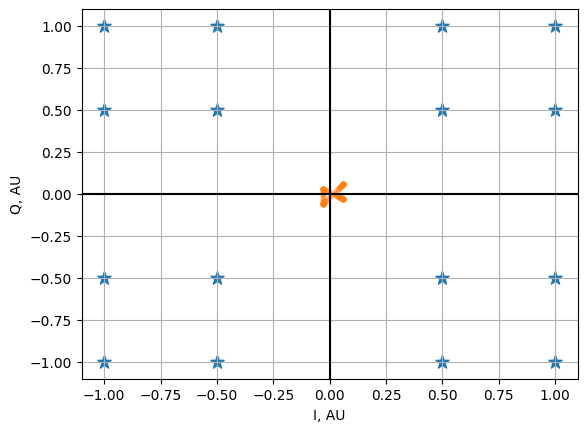

In [3]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(qam16_constellation, s=100, marker="*")
plot_iq_constellation(received_signal, s=10, iq_units=(17.0, "AU"), alpha=0.25)

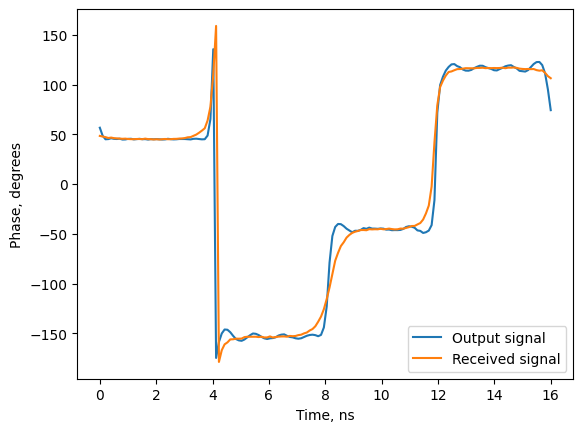

In [6]:
plot_phase(output_signal, label="Output signal")
plot_phase(received_signal, label="Received signal")
plt.legend()

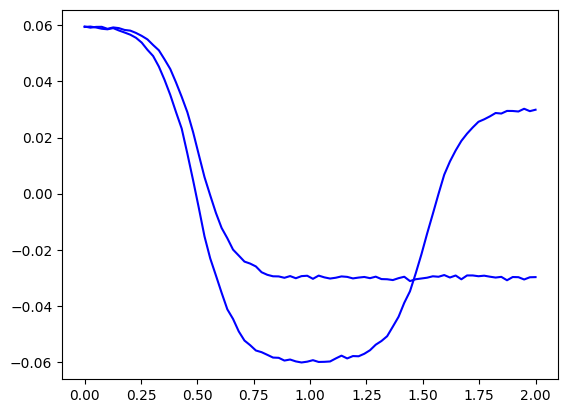

In [7]:
plot_eye_diagram(received_signal[0], color="blue")
plot_eye_diagram(received_signal[1], color="blue")